# Model monitoring

Read-only analysis of everything the pipeline has written for the credit-default models:

1. **Inventory**: which models have predictions, PSI and performance outputs, and when labels mature
2. **Performance** (needs matured `30dpd_6mob` labels): AUC / Gini, calibration, KS, lift
3. **Score stability**: prediction distribution and prediction PSI per month
4. **Feature drift**: feature PSI heatmaps per model
5. **Root-cause diagnostics**: missing rates, the clickstream window effect, clickstream coverage
6. **Model comparison**: models scoring the same months
7. **Monitoring summary**: one row per model and month, with an action flag

The notebook only reads `datamart/gold/*`. It never rescores, retrains or overwrites anything.
Run from `notebooks/` (or the project root) with pandas, scikit-learn and matplotlib. Spark is not needed.

In [4]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm, ListedColormap
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from scripts.model_monitoring import read_partition  # same reader the pipeline uses

GOLD = ROOT / "datamart" / "gold"
LABEL_DEF = "30dpd_6mob"
LABEL_LAG_MONTHS = 6

# Thresholds (PSI matches utils/psi.py; performance ones are monitoring policy)
PSI_WARNING, PSI_ALERT = 0.10, 0.25
AUC_FLOOR = 0.75          # absolute floor for an acceptable model
AUC_DROP_WARNING = 0.03   # drop vs the model's first matured month
CALIBRATION_TOLERANCE = 0.20  # |mean prediction / default rate - 1|

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [5]:
# Chart style: recessive grid/axes, thin marks, text in ink colours (not series colours)
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"stable": "#0ca30c", "warning": "#fab219", "alert": "#d03b3b"}
SEQ_BLUE = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
    "figure.dpi": 110,
})

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

def short(model_name):
    return model_name.replace(".pkl", "").replace("credit_model_", "")

## 1. Load the gold outputs

In [6]:
def load_csvs(pattern):
    files = sorted(GOLD.glob(pattern))
    frames = []
    for file in files:
        frame = pd.read_csv(file)
        # Some exports pad headers and string values with spaces.
        # Normalize before concatenating so padded headers do not become extra columns.
        frame.columns = frame.columns.str.strip()
        if frame.columns.duplicated().any():
            raise ValueError(f"{file}: duplicate columns after trimming whitespace")
        for col in frame.select_dtypes(include=["object", "string"]).columns:
            frame[col] = frame[col].str.strip()
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

psi = load_csvs("model_monitoring/*/psi_*.csv")
perf = load_csvs("model_performance/*/performance_*.csv")
preds = load_csvs("model_predictions/*/*.csv")

for frame, cols in [(psi, ["snapshot_date", "reference_start_date", "reference_end_date"]),
                    (perf, ["evaluation_date", "prediction_snapshot_date"]),
                    (preds, ["snapshot_date"])]:
    for c in cols:
        if c in frame:
            frame[c] = pd.to_datetime(frame[c])

labels = pd.concat([read_partition(p) for p in sorted((GOLD / "label_store").glob("gold_label_store_*.parquet"))],
                   ignore_index=True)
labels = labels[labels["label_def"].eq(LABEL_DEF)]
labels["snapshot_date"] = pd.to_datetime(labels["snapshot_date"])
labels["feature_snapshot_date"] = pd.to_datetime(labels["feature_snapshot_date"])

features = pd.concat([read_partition(p) for p in sorted((GOLD / "features_store").glob("gold_features_store_*.parquet"))],
                     ignore_index=True)
features["snapshot_date"] = pd.to_datetime(features["snapshot_date"])

if preds["model_name"].isna().any() or preds["model_name"].eq("").any():
    raise ValueError("Prediction CSVs contain missing model names; check the source exports")
MODELS = sorted(preds["model_name"].unique())
MODEL_COLOR = {m: SERIES[i] for i, m in enumerate(MODELS)}  # fixed order, never cycled
MODEL_FEATURES = sorted(psi.loc[psi["scope"].eq("feature"), "feature_name"].unique())

print(f"PSI rows {len(psi):,} | performance rows {len(perf):,} | predictions {len(preds):,} "
      f"| labels {len(labels):,} | feature rows {len(features):,}")
print("Models:", ", ".join(MODELS))
print("Label observation months:", labels["snapshot_date"].min().date(), "->", labels["snapshot_date"].max().date())

PSI rows 156 | performance rows 6 | predictions 7,968 | labels 8,974 | feature rows 11,974
Models: credit_model_2024_01_01.pkl, credit_model_2024_07_01.pkl, credit_model_2024_09_01.pkl
Label observation months: 2023-07-01 -> 2024-12-01


## 2. Inventory

A prediction for application month *M* can only be evaluated once its label is observed in *M + 6*.
`matured_cohorts` counts prediction months whose label partition already exists.

In [7]:
last_label = labels["snapshot_date"].max()
rows = []
for m in MODELS:
    p = preds[preds["model_name"].eq(m)]
    months = sorted(p["snapshot_date"].unique())
    rows.append({
        "model": short(m),
        "first_prediction": months[0].date(),
        "last_prediction": months[-1].date(),
        "prediction_months": len(months),
        "psi_months": psi.loc[psi["model_name"].eq(m), "snapshot_date"].nunique(),
        "performance_months": perf.loc[perf["model_name"].eq(m), "evaluation_date"].nunique() if len(perf) else 0,
        "matured_cohorts": sum(pd.Timestamp(d) + pd.DateOffset(months=LABEL_LAG_MONTHS) <= last_label for d in months),
        "first_label_due": (months[0] + pd.DateOffset(months=LABEL_LAG_MONTHS)).date(),
        "psi_reference": (f"{psi.loc[psi.model_name.eq(m), 'reference_start_date'].min():%Y-%m} -> "
                          f"{psi.loc[psi.model_name.eq(m), 'reference_end_date'].max():%Y-%m}"
                          if psi["model_name"].eq(m).any() else "none"),
    })
inventory = pd.DataFrame(rows)
inventory

,model,first_prediction,last_prediction,prediction_months,psi_months,performance_months,matured_cohorts,first_label_due,psi_reference
0,2024_01_01,2024-01-01,2024-06-01,6,6,6,6,2024-07-01,2023-01 -> 2023-04
1,2024_07_01,2024-07-01,2024-12-01,6,6,0,0,2025-01-01,2023-01 -> 2023-10
2,2024_09_01,2024-09-01,2024-12-01,4,0,0,0,2025-03-01,none


## 3. Performance on matured labels

First, the performance CSVs written by `scripts/model_performance.py`. Then the same cohorts are
recomputed straight from predictions + labels to add metrics the job doesn't store: KS, Brier, log loss,
top-decile capture and a calibration ratio. Only cohorts with **complete** label coverage get outcome metrics,
the same rule the pipeline uses, so a partially labelled subset can't bias the numbers.

In [8]:
if len(perf):
    display(perf.sort_values(["model_name", "evaluation_date"])
            [["model_name", "evaluation_date", "prediction_snapshot_date", "n_predictions", "label_coverage",
              "auc", "gini", "default_rate", "mean_prediction", "status"]])
else:
    print("No performance CSVs yet: no prediction cohort has matured labels.")

,model_name,evaluation_date,prediction_snapshot_date,n_predictions,label_coverage,auc,gini,default_rate,mean_prediction,status
0,credit_model_2024_01_01.pkl,2024-07-01,2024-01-01,485,1.0,0.870194,0.740388,0.296907,0.278957,ok
1,credit_model_2024_01_01.pkl,2024-08-01,2024-02-01,518,1.0,0.836790,0.673579,0.283784,0.299742,ok
2,credit_model_2024_01_01.pkl,2024-09-01,2024-03-01,511,1.0,0.828457,0.656914,0.328767,0.305352,ok
3,credit_model_2024_01_01.pkl,2024-10-01,2024-04-01,513,1.0,0.829904,0.659808,0.276803,0.292567,ok
4,credit_model_2024_01_01.pkl,2024-11-01,2024-05-01,491,1.0,0.840790,0.681581,0.303462,0.301590,ok
5,credit_model_2024_01_01.pkl,2024-12-01,2024-06-01,498,1.0,0.878529,0.757058,0.311245,0.290452,ok


In [9]:
def ks_stat(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return float(np.max(tpr - fpr))

def top_decile_capture(y, s):
    cut = np.quantile(s, 0.9)
    return float(y[s >= cut].sum() / y.sum())

scored = preds.merge(
    labels[["customer_id", "feature_snapshot_date", "label", "snapshot_date"]]
        .rename(columns={"snapshot_date": "label_date", "feature_snapshot_date": "snapshot_date"}),
    on=["customer_id", "snapshot_date"], how="left")

metric_rows = []
for (m, d), g in scored.groupby(["model_name", "snapshot_date"]):
    coverage = g["label"].notna().mean()
    row = {"model_name": m, "prediction_date": d, "evaluation_date": d + pd.DateOffset(months=LABEL_LAG_MONTHS),
           "n": len(g), "label_coverage": coverage, "mean_prediction": g["model_predictions"].mean()}
    if coverage == 1 and g["label"].nunique() == 2:
        y, s = g["label"].to_numpy(int), g["model_predictions"].to_numpy(float)
        row.update(auc=roc_auc_score(y, s), ks=ks_stat(y, s), brier=brier_score_loss(y, s),
                   log_loss=log_loss(y, s), top_decile_capture=top_decile_capture(y, s), default_rate=y.mean())
        row["gini"] = 2 * row["auc"] - 1
        row["calibration_ratio"] = row["mean_prediction"] / row["default_rate"]
    metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
matured = metrics.dropna(subset=["auc"]).copy()

if len(matured):
    # Cross-check against the pipeline's own CSVs
    if len(perf):
        check = matured.merge(perf, on=["model_name", "evaluation_date"], suffixes=("", "_job"))
        print("Max |AUC - AUC from job|:", float((check["auc"] - check["auc_job"]).abs().max()))
    display(matured[["model_name", "prediction_date", "evaluation_date", "n", "auc", "gini", "ks",
                     "brier", "log_loss", "top_decile_capture", "default_rate", "mean_prediction",
                     "calibration_ratio"]].round(4))
else:
    print("No cohort has complete labels yet.")

Max |AUC - AUC from job|: 0.0


,model_name,prediction_date,evaluation_date,n,auc,gini,ks,brier,log_loss,top_decile_capture,default_rate,mean_prediction,calibration_ratio
0,credit_model_2024_01_01.pkl,2024-01-01,2024-07-01,485,0.8702,0.7404,0.6029,0.1401,0.4377,0.2778,0.2969,0.2790,0.9395
1,credit_model_2024_01_01.pkl,2024-02-01,2024-08-01,518,0.8368,0.6736,0.5396,0.1394,0.4402,0.2993,0.2838,0.2997,1.0562
2,credit_model_2024_01_01.pkl,2024-03-01,2024-09-01,511,0.8285,0.6569,0.5132,0.1538,0.4767,0.2619,0.3288,0.3054,0.9288
3,credit_model_2024_01_01.pkl,2024-04-01,2024-10-01,513,0.8299,0.6598,0.5595,0.1497,0.4616,0.2606,0.2768,0.2926,1.0569
4,credit_model_2024_01_01.pkl,2024-05-01,2024-11-01,491,0.8408,0.6816,0.5635,0.1417,0.4469,0.2886,0.3035,0.3016,0.9938
5,credit_model_2024_01_01.pkl,2024-06-01,2024-12-01,498,0.8785,0.7571,0.6161,0.1313,0.4208,0.2839,0.3112,0.2905,0.9332


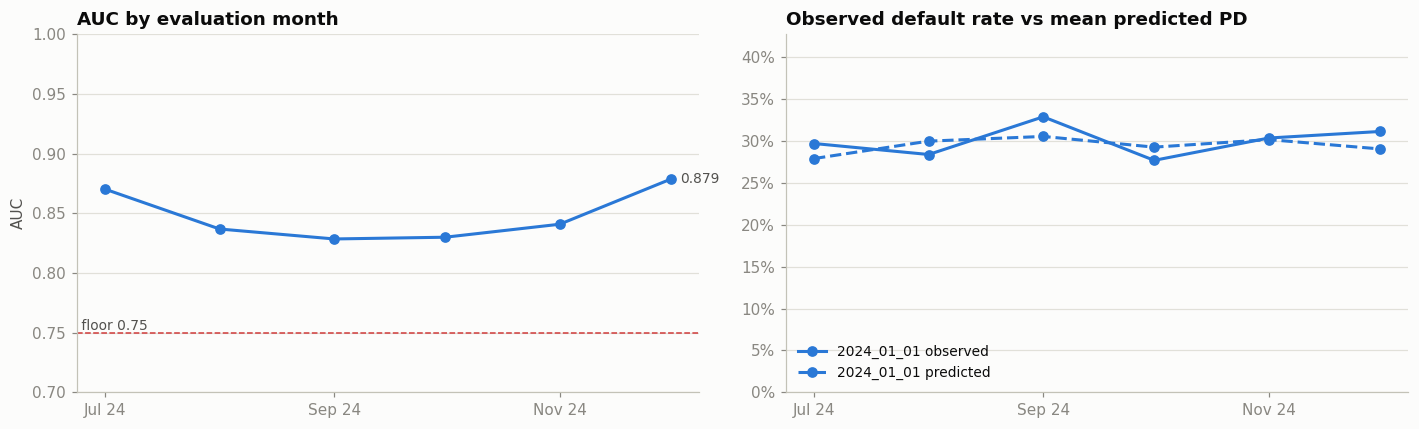

In [10]:
if len(matured):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ax = axes[0]
    for m, g in matured.groupby("model_name"):
        ax.plot(g["evaluation_date"], g["auc"], marker="o", color=MODEL_COLOR[m], label=short(m))
        ax.annotate(f"{g['auc'].iloc[-1]:.3f}", (g["evaluation_date"].iloc[-1], g["auc"].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
    ax.axhline(AUC_FLOOR, color=STATUS["alert"], lw=1, ls="--")
    ax.text(ax.get_xlim()[0], AUC_FLOOR, f" floor {AUC_FLOOR}", va="bottom", color=INK2, fontsize=9)
    ax.set_ylim(min(0.7, matured["auc"].min() - 0.02), 1)
    ax.set_title("AUC by evaluation month")
    ax.set_ylabel("AUC")
    month_axis(ax)
    if matured["model_name"].nunique() > 1:
        ax.legend()

    # Observed default rate vs mean predicted PD (same unit, so one axis)
    ax = axes[1]
    for m, g in matured.groupby("model_name"):
        c = MODEL_COLOR[m]
        ax.plot(g["evaluation_date"], g["default_rate"], marker="o", color=c, label=f"{short(m)} observed")
        ax.plot(g["evaluation_date"], g["mean_prediction"], marker="o", ls="--", color=c, label=f"{short(m)} predicted")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, max(matured["default_rate"].max(), matured["mean_prediction"].max()) * 1.3)
    ax.set_title("Observed default rate vs mean predicted PD")
    month_axis(ax)
    ax.legend(loc="lower left", fontsize=9)
    fig.tight_layout()

n  defaults  mean_pd  default_rate  cum_capture   lift
model_name                  decile                                                          
credit_model_2024_01_01.pkl 1       302     251.0    0.780         0.831        0.277  2.770
                            2       301     195.0    0.623         0.648        0.493  2.159
                            3       302     146.0    0.438         0.483        0.654  1.611
                            4       301     113.0    0.274         0.375        0.779  1.251
                            5       302      74.0    0.192         0.245        0.861  0.817
                            6       301      47.0    0.158         0.156        0.913  0.520
                            7       302      34.0    0.139         0.113        0.950  0.375
                            8       301      19.0    0.127         0.063        0.971  0.210
                            9       302      21.0    0.115         0.070        0.994  0.232
                            10      302       5.0    0.103         0.017        1.000  0.055

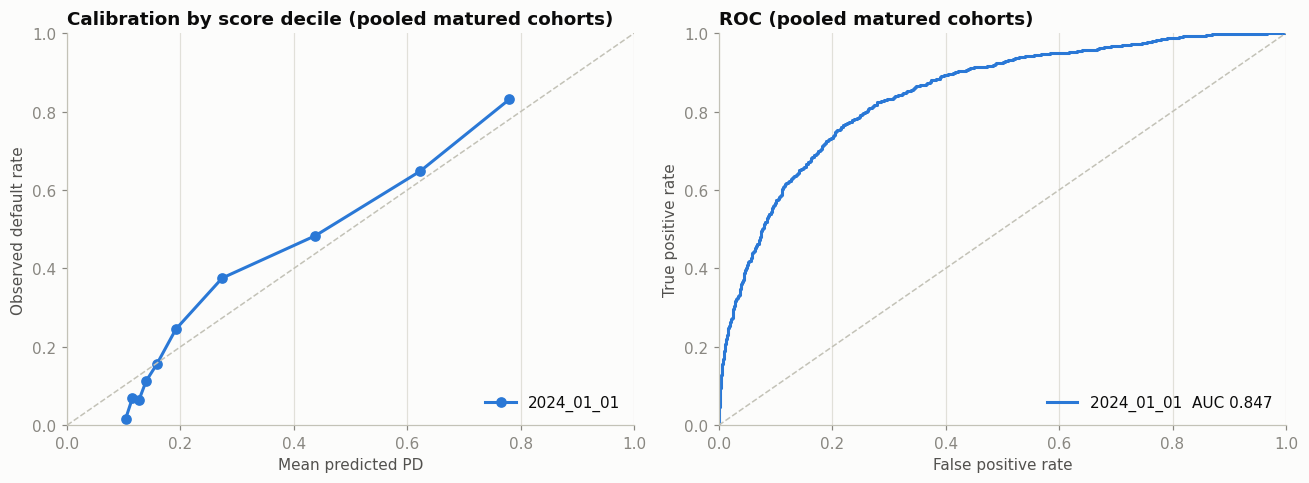

In [11]:
# Calibration and ROC, pooling every matured cohort per model
if len(matured):
    pooled = scored.merge(matured[["model_name", "prediction_date"]],
                          left_on=["model_name", "snapshot_date"], right_on=["model_name", "prediction_date"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for m, g in pooled.groupby("model_name"):
        c = MODEL_COLOR[m]
        g = g.assign(decile=pd.qcut(g["model_predictions"].rank(method="first"), 10, labels=False))
        cal = g.groupby("decile").agg(pred=("model_predictions", "mean"), obs=("label", "mean"))
        axes[0].plot(cal["pred"], cal["obs"], marker="o", color=c, label=short(m))
        fpr, tpr, _ = roc_curve(g["label"], g["model_predictions"])
        axes[1].plot(fpr, tpr, color=c, label=f"{short(m)}  AUC {roc_auc_score(g['label'], g['model_predictions']):.3f}")
    for ax in axes:
        ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(axis="both")
        ax.legend(loc="lower right")
    axes[0].set(title="Calibration by score decile (pooled matured cohorts)",
                xlabel="Mean predicted PD", ylabel="Observed default rate")
    axes[1].set(title="ROC (pooled matured cohorts)", xlabel="False positive rate", ylabel="True positive rate")
    fig.tight_layout()

    lift = (pooled.assign(decile=pooled.groupby("model_name")["model_predictions"]
                          .transform(lambda s: 10 - pd.qcut(s.rank(method="first"), 10, labels=False)))
            .groupby(["model_name", "decile"])
            .agg(n=("label", "size"), defaults=("label", "sum"), mean_pd=("model_predictions", "mean")))
    lift["default_rate"] = lift["defaults"] / lift["n"]
    lift["cum_capture"] = lift.groupby(level=0)["defaults"].cumsum() / lift.groupby(level=0)["defaults"].transform("sum")
    lift["lift"] = lift["default_rate"] / (lift.groupby(level=0)["defaults"].transform("sum")
                                           / lift.groupby(level=0)["n"].transform("sum"))
    display(lift.round(3))  # decile 1 = riskiest 10%

## 4. Score stability

Prediction PSI compares each month's score distribution with the model's fixed reference (score buckets
0.1 … 0.9). It needs no labels, so it is the earliest warning for models whose labels haven't matured.

n   mean    p10  median    p90  share_above_50
model_name                  snapshot_date                                                  
credit_model_2024_01_01.pkl 2024-01-01     485  0.279  0.109   0.158  0.667           0.190
                            2024-02-01     518  0.300  0.113   0.177  0.692           0.216
                            2024-03-01     511  0.305  0.110   0.180  0.716           0.223
                            2024-04-01     513  0.293  0.110   0.173  0.712           0.209
                            2024-05-01     491  0.302  0.110   0.165  0.728           0.240
                            2024-06-01     498  0.290  0.108   0.168  0.698           0.207
credit_model_2024_07_01.pkl 2024-07-01     505  0.211  0.075   0.093  0.571           0.145
                            2024-08-01     543  0.206  0.075   0.093  0.544           0.118
                            2024-09-01     493  0.216  0.075   0.093  0.562           0.144
                            2024-10-01     456  0.190  0.075   0.090  0.515           0.105
                            2024-11-01     488  0.202  0.075   0.092  0.515           0.105
                            2024-12-01     515  0.177  0.075   0.088  0.479           0.093
credit_model_2024_09_01.pkl 2024-09-01     493  0.214  0.067   0.111  0.478           0.079
                            2024-10-01     456  0.194  0.071   0.108  0.469           0.077
                            2024-11-01     488  0.208  0.073   0.113  0.477           0.070
                            2024-12-01     515  0.182  0.068   0.104  0.442           0.037

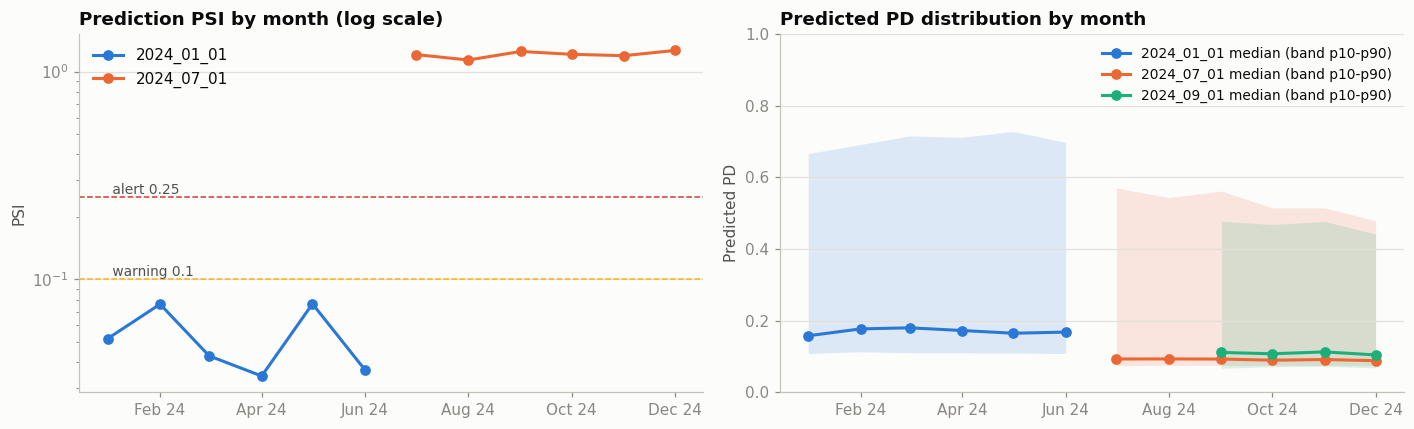

In [12]:
pred_psi = psi[psi["scope"].eq("prediction")].sort_values("snapshot_date")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for m, g in pred_psi.groupby("model_name"):
    ax.plot(g["snapshot_date"], g["psi"], marker="o", color=MODEL_COLOR[m], label=short(m))
for level, name in [(PSI_WARNING, "warning"), (PSI_ALERT, "alert")]:
    ax.axhline(level, color=STATUS[name], lw=1, ls="--")
    ax.text(pred_psi["snapshot_date"].min(), level, f" {name} {level}", va="bottom", color=INK2, fontsize=9)
ax.set_yscale("log")
ax.set_title("Prediction PSI by month (log scale)")
ax.set_ylabel("PSI")
month_axis(ax)
ax.legend()

ax = axes[1]
q = (preds.groupby(["model_name", "snapshot_date"])["model_predictions"]
     .quantile([0.1, 0.5, 0.9]).unstack().reset_index())
for m, g in q.groupby("model_name"):
    c = MODEL_COLOR[m]
    ax.fill_between(g["snapshot_date"], g[0.1], g[0.9], color=c, alpha=0.15, lw=0)
    ax.plot(g["snapshot_date"], g[0.5], color=c, marker="o", label=f"{short(m)} median (band p10-p90)")
ax.set_ylim(0, 1)
ax.set_title("Predicted PD distribution by month")
ax.set_ylabel("Predicted PD")
month_axis(ax)
ax.legend(fontsize=9)
fig.tight_layout()

score_summary = (preds.groupby(["model_name", "snapshot_date"])["model_predictions"]
                 .agg(n="size", mean="mean", p10=lambda s: s.quantile(.1), median="median",
                      p90=lambda s: s.quantile(.9), share_above_50=lambda s: (s >= .5).mean()))
score_summary.round(3)

## 5. Feature drift (PSI)

One heatmap per model: rows are model features, columns are monitoring months. Colour bands follow the PSI
thresholds; the number in each cell is the PSI. A value of about **25.3** is the ceiling the ε = 1e-6 floor
allows. It means the whole month fell into buckets that were empty in the reference, usually the
missing-value bucket.

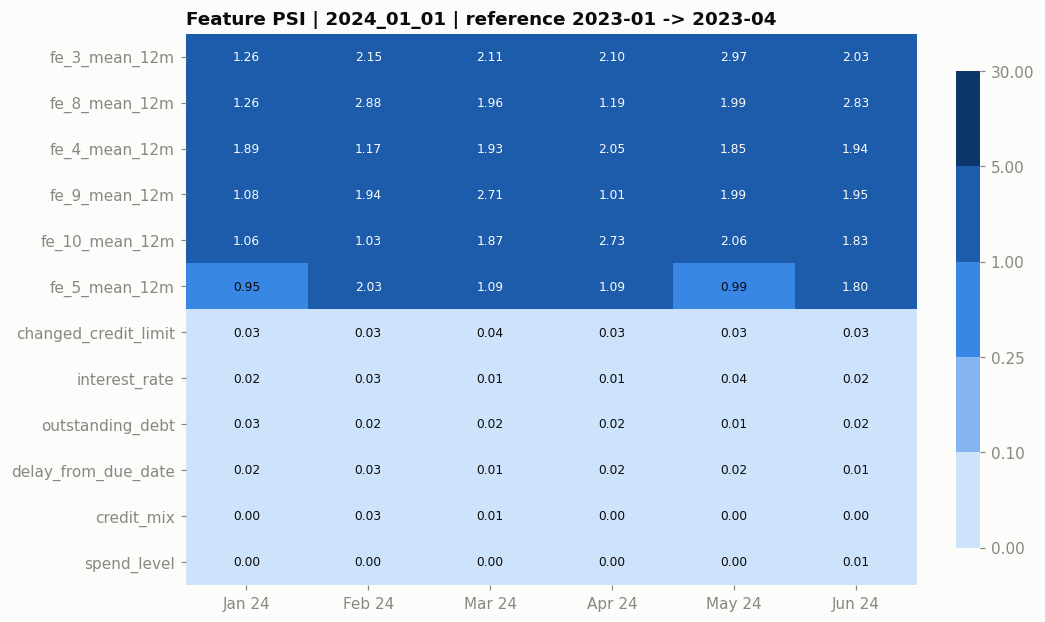

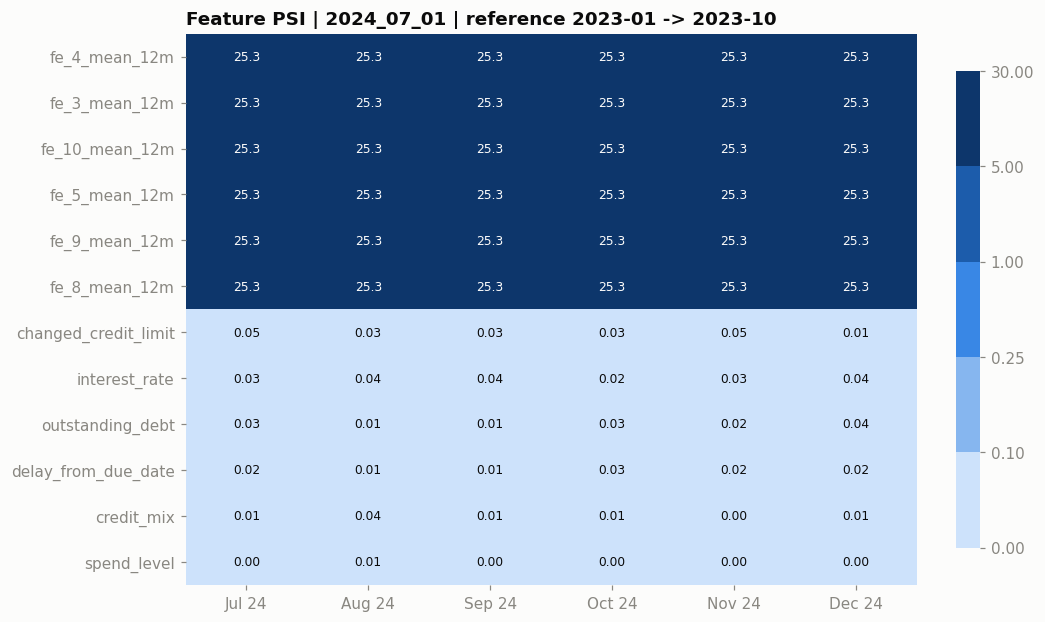

In [13]:
bounds = [0, PSI_WARNING, PSI_ALERT, 1, 5, 30]
cmap, norm = ListedColormap(SEQ_BLUE), BoundaryNorm(bounds, len(SEQ_BLUE))
feat_psi = psi[psi["scope"].eq("feature")]

for m, g in feat_psi.groupby("model_name"):
    grid = g.pivot(index="feature_name", columns="snapshot_date", values="psi")
    grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(1.1 * grid.shape[1] + 3, 0.38 * grid.shape[0] + 1.2))
    im = ax.imshow(grid.clip(upper=29.9).to_numpy(), cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(grid.shape[1]), [f"{d:%b %y}" for d in grid.columns])
    ax.set_yticks(range(grid.shape[0]), grid.index)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}" if v < 10 else f"{v:.1f}", ha="center", va="center", fontsize=8,
                    color=INK if v < 1 else SURFACE)
    ref = g[["reference_start_date", "reference_end_date"]].iloc[0]
    ax.set_title(f"Feature PSI | {short(m)} | reference {ref.iloc[0]:%Y-%m} -> {ref.iloc[1]:%Y-%m}")
    cb = fig.colorbar(im, ax=ax, ticks=bounds, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.tick_params(colors=MUTED)
    fig.tight_layout()

### Additional slide graph: feature PSI across 2024

One compact heatmap combines V1 (Jan–Jun) and V2 (Jul–Dec), separated at the deployment change.
Colours show stable, warning and alert bands; annotations retain the actual PSI values.
Each half uses its own model’s fixed reference, shown above the chart. The prediction PSI finding is a text note.
The original per-model heatmaps are retained above. PNG and SVG exports are saved to `notebooks/figures/`.
Presentation export: 11 × 5.5 inches at 200 DPI, with 12pt cell annotations and 13pt tick labels.
Use `figures/feature_psi_2024_v1_v2_large_text.png` for the larger-text slide image.

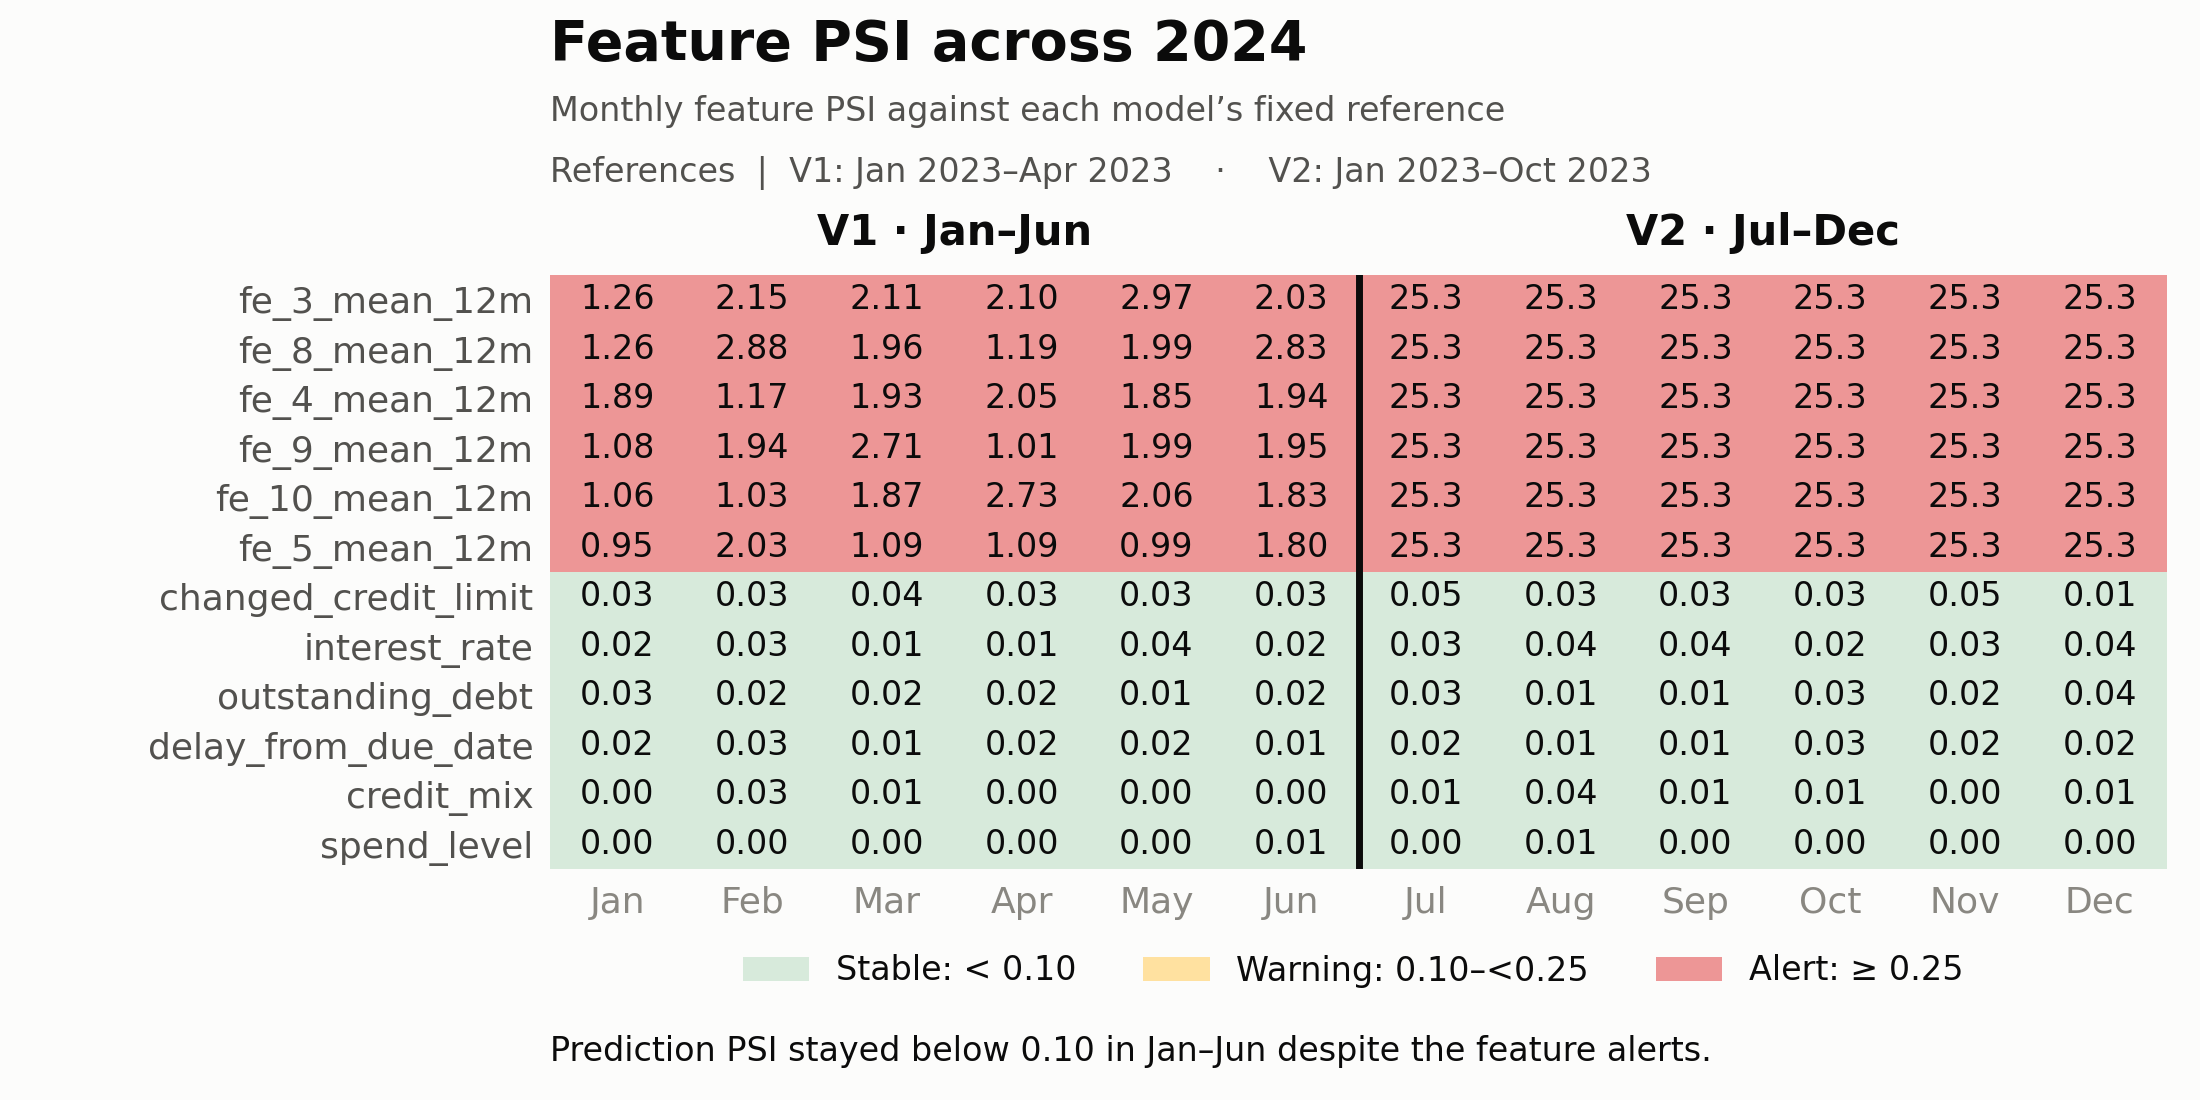

In [ ]:
# Additional slide graphic; the original per-model heatmaps are retained above.
from matplotlib.patches import Patch

slide_months = pd.date_range("2024-01-01", "2024-12-01", freq="MS")
v1, v2 = "credit_model_2024_01_01.pkl", "credit_model_2024_07_01.pkl"
slide_features = psi.loc[
    psi["scope"].eq("feature")
    & ((psi["model_name"].eq(v1) & psi["snapshot_date"].isin(slide_months[:6]))
       | (psi["model_name"].eq(v2) & psi["snapshot_date"].isin(slide_months[6:])))
].copy()
if slide_features.duplicated(["feature_name", "snapshot_date"]).any():
    raise ValueError("Expected one feature PSI value per deployed model and month")
slide_grid = slide_features.pivot(index="feature_name", columns="snapshot_date", values="psi")
slide_grid = slide_grid.reindex(columns=slide_months)
slide_grid = slide_grid.loc[slide_grid.mean(axis=1).sort_values(ascending=False).index]
if slide_grid.empty:
    raise ValueError("No feature PSI results found for V1/V2 in 2024")

# Map to three discrete bands; PSI magnitudes within a band share a colour.
slide_bands = pd.DataFrame(
    np.where(slide_grid >= PSI_ALERT, 2, np.where(slide_grid >= PSI_WARNING, 1, 0)),
    index=slide_grid.index, columns=slide_grid.columns,
).astype(float).mask(slide_grid.isna())
slide_colors = ["#d7eadb", "#ffe1a0", "#ed9696"]
slide_cmap = ListedColormap(slide_colors)
slide_cmap.set_bad("#eeeeec")
fig_slide, ax_slide = plt.subplots(figsize=(11, 5.5))
fig_slide.subplots_adjust(left=0.25, right=0.985, top=0.75, bottom=0.21)
ax_slide.imshow(np.ma.masked_invalid(slide_bands.to_numpy()), cmap=slide_cmap,
               norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3), aspect="auto")
ax_slide.set_xticks(range(12), slide_months.strftime("%b"), fontsize=13)
ax_slide.set_yticks(range(len(slide_grid)), slide_grid.index, fontsize=13, color=INK2)
ax_slide.tick_params(length=0, pad=6)
ax_slide.grid(False)
for spine in ax_slide.spines.values():
    spine.set_visible(False)
for (i, j), value in np.ndenumerate(slide_grid.to_numpy()):
    label = "—" if np.isnan(value) else (f"{value:.2f}" if value < 10 else f"{value:.1f}")
    ax_slide.text(j, i, label, ha="center", va="center", fontsize=12, color=INK)
ax_slide.axvline(5.5, color=INK, linewidth=2.5)
ax_slide.text(0.25, 1.035, "V1 · Jan–Jun", transform=ax_slide.transAxes,
              ha="center", va="bottom", fontsize=15, weight="bold")
ax_slide.text(0.75, 1.035, "V2 · Jul–Dec", transform=ax_slide.transAxes,
              ha="center", va="bottom", fontsize=15, weight="bold")
fig_slide.text(0.25, 0.945, "Feature PSI across 2024", fontsize=20, weight="bold", color=INK)
fig_slide.text(0.25, 0.89, "Monthly feature PSI against each model’s fixed reference",
               fontsize=12, color=INK2)
reference_notes = []
for version, model in [("V1", v1), ("V2", v2)]:
    ref = slide_features.loc[slide_features["model_name"].eq(model),
                             ["reference_start_date", "reference_end_date"]].drop_duplicates()
    if len(ref) != 1:
        raise ValueError(f"Expected one fixed reference period for {version}")
    start, end = ref.iloc[0]
    reference_notes.append(f"{version}: {start:%b %Y}–{end:%b %Y}")
fig_slide.text(0.25, 0.835, "References  |  " + "    ·    ".join(reference_notes), fontsize=12, color=INK2)
fig_slide.legend(handles=[
    Patch(facecolor=slide_colors[0], label="Stable: < 0.10"),
    Patch(facecolor=slide_colors[1], label="Warning: 0.10–<0.25"),
    Patch(facecolor=slide_colors[2], label="Alert: ≥ 0.25"),
], loc="lower center", bbox_to_anchor=(0.615, 0.075), ncol=3, fontsize=12, frameon=False)
jan_jun_score_psi = psi.loc[
    psi["scope"].eq("prediction") & psi["model_name"].eq(v1)
    & psi["snapshot_date"].isin(slide_months[:6]), ["snapshot_date", "psi"]]
if (len(jan_jun_score_psi) == 6 and jan_jun_score_psi["snapshot_date"].nunique() == 6
        and jan_jun_score_psi["psi"].notna().all()
        and jan_jun_score_psi["psi"].lt(PSI_WARNING).all()):
    prediction_note = "Prediction PSI stayed below 0.10 in Jan–Jun despite the feature alerts."
else:
    prediction_note = "Prediction PSI did not stay below 0.10 in every Jan–Jun month, or monitoring is incomplete."
fig_slide.text(0.25, 0.035, prediction_note, fontsize=12, color=INK)

# Compact canvas keeps labels readable when placed on a presentation slide.
slide_output = ROOT / "notebooks" / "figures"
slide_output.mkdir(parents=True, exist_ok=True)
fig_slide.savefig(slide_output / "feature_psi_2024_v1_v2.png", dpi=200)
fig_slide.savefig(slide_output / "feature_psi_2024_v1_v2.svg")
# Separate filename for swapping the larger-text version into a slide.
fig_slide.savefig(slide_output / "feature_psi_2024_v1_v2_large_text.png", dpi=200)
plt.show()


In [15]:
# Status counts per model-month, plus the features that alert every single month
status_counts = (feat_psi.groupby(["model_name", "snapshot_date", "status"]).size()
                 .unstack(fill_value=0).reindex(columns=["stable", "warning", "alert"], fill_value=0))
display(status_counts)

always_alert = (feat_psi.assign(is_alert=feat_psi["status"].eq("alert"))
                .groupby(["model_name", "feature_name"])["is_alert"].mean()
                .loc[lambda s: s.eq(1)].reset_index()
                .groupby("model_name")["feature_name"].apply(list))
print("Features on alert in every monitored month:")
for m, feats in always_alert.items():
    print(f"  {short(m)}: {', '.join(feats)}")

status                                     stable  warning  alert
model_name                  snapshot_date                        
credit_model_2024_01_01.pkl 2024-01-01          6        0      6
                            2024-02-01          6        0      6
                            2024-03-01          6        0      6
                            2024-04-01          6        0      6
                            2024-05-01          6        0      6
                            2024-06-01          6        0      6
credit_model_2024_07_01.pkl 2024-07-01          6        0      6
                            2024-08-01          6        0      6
                            2024-09-01          6        0      6
                            2024-10-01          6        0      6
                            2024-11-01          6        0      6
                            2024-12-01          6        0      6

Features on alert in every monitored month:
  2024_01_01: fe_10_mean_12m, fe_3_mean_12m, fe_4_mean_12m, fe_5_mean_12m, fe_8_mean_12m, fe_9_mean_12m
  2024_07_01: fe_10_mean_12m, fe_3_mean_12m, fe_4_mean_12m, fe_5_mean_12m, fe_8_mean_12m, fe_9_mean_12m


## 6. Root-cause diagnostics

PSI shows *that* a feature moved, not *why*. Three checks explain most of what the heatmaps show:

* **Missing rate**: a feature that becomes null all at once drives PSI to its ceiling.
* **Clickstream window length**: `fe_*_mean_12m` is a mean over up to 12 months, but clickstream data only
  starts in Jan 2023. Early application months average over fewer months, so their spread is much wider.
  A reference built from those months makes later, full-window months look like drift.
* **Clickstream coverage**: the share of applicants with any clickstream history (`has_clickstream`).

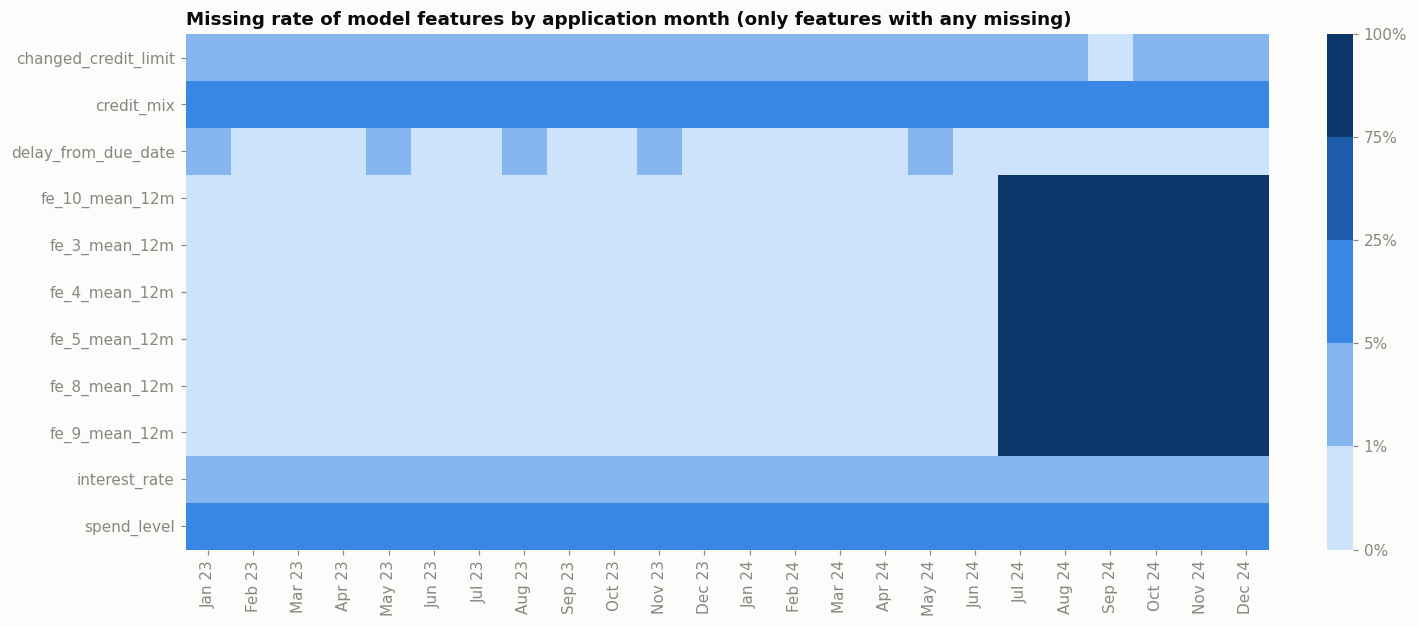

In [16]:
missing = features.groupby("snapshot_date")[MODEL_FEATURES].apply(lambda f: f.isna().mean()).T
missing = missing.loc[missing.max(axis=1) > 0]
if len(missing):
    fig, ax = plt.subplots(figsize=(13, 0.4 * len(missing) + 1.4))
    im = ax.imshow(missing.to_numpy(), cmap=ListedColormap(SEQ_BLUE),
                   norm=BoundaryNorm([0, 0.01, 0.05, 0.25, 0.75, 1.0001], len(SEQ_BLUE)), aspect="auto")
    ax.set_xticks(range(missing.shape[1]), [f"{d:%b %y}" for d in missing.columns], rotation=90)
    ax.set_yticks(range(missing.shape[0]), missing.index)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title("Missing rate of model features by application month (only features with any missing)")
    fig.tight_layout()
else:
    print("No model feature has missing values in any month.")

snapshot_date,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01
months_of_history,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0
mean_std_fe,100.0,72.1,58.7,50.4,45.6,43.3,38.6,36.7,35.0,32.2,31.5,29.5,30.7,30.2,30.0,29.7,29.4,30.8,NaN,NaN,NaN,NaN,NaN,NaN
has_clickstream,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


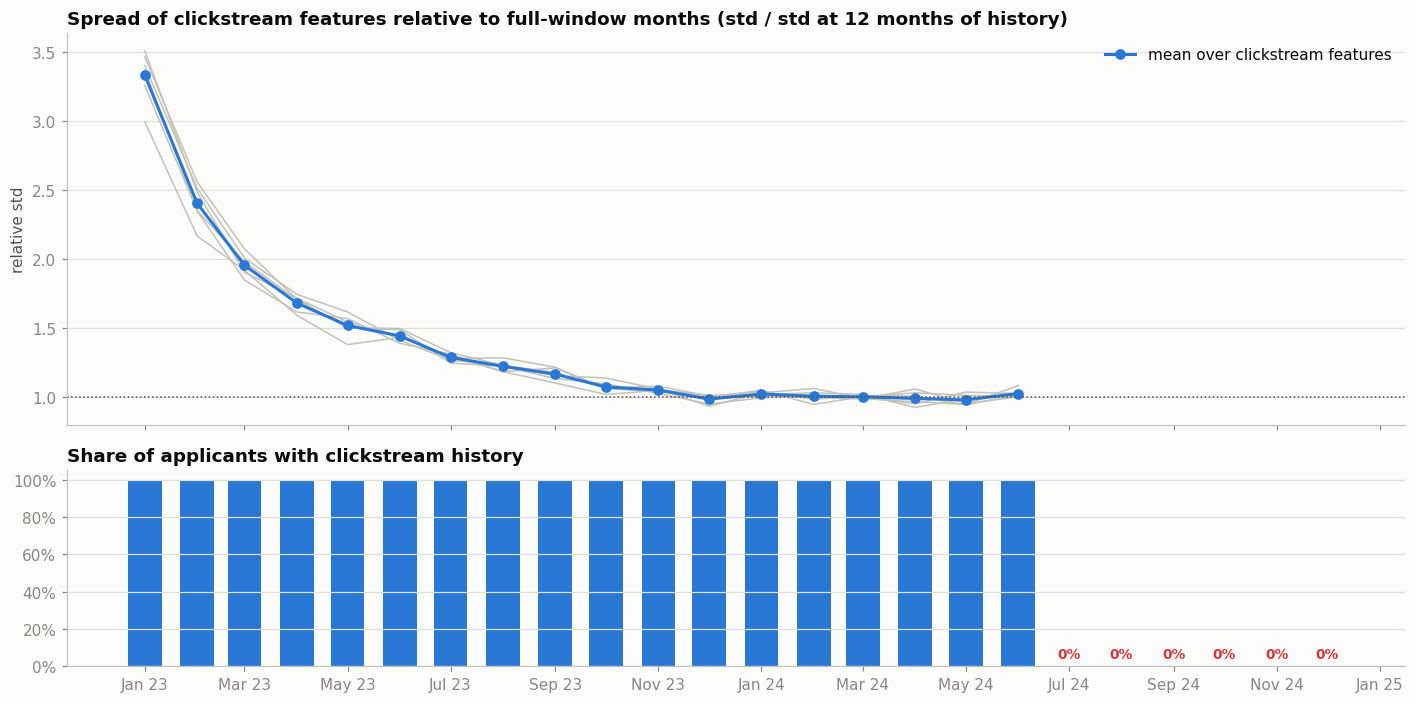

In [17]:
cs_cols = [c for c in MODEL_FEATURES if c.startswith("fe_")]
by_month = features.groupby("snapshot_date")
spread = by_month[cs_cols].std()
history_months = pd.Series(
    [min(12, (d.year - 2023) * 12 + d.month) for d in spread.index], index=spread.index)
coverage = by_month["has_clickstream"].mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
full = spread.index[history_months.eq(12)]
norm_spread = spread / spread.loc[full].mean() if len(full) else spread / spread.iloc[-1]
for c in cs_cols:
    ax.plot(norm_spread.index, norm_spread[c], color=AXIS, lw=1)
ax.plot(norm_spread.index, norm_spread.mean(axis=1), color=SERIES[0], marker="o", label="mean over clickstream features")
ax.axhline(1, color=INK2, lw=1, ls=":")
ax.set_title("Spread of clickstream features relative to full-window months (std / std at 12 months of history)")
ax.set_ylabel("relative std")
ax.legend(loc="upper right")

ax = axes[1]
ax.bar(coverage.index, coverage.values, width=20, color=SERIES[0])
for d, v in coverage[coverage.eq(0)].items():
    ax.text(d, 0.03, "0%", ha="center", va="bottom", color=STATUS["alert"], fontsize=9, fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 1.05)
ax.set_title("Share of applicants with clickstream history")
month_axis(ax)
fig.tight_layout()

pd.DataFrame({"months_of_history": history_months, "mean_std_fe": spread.mean(axis=1).round(1),
              "has_clickstream": coverage.round(3)}).T

In [18]:
# How each model's PSI reference lines up with full-window months
refs = (psi.groupby("model_name")[["reference_start_date", "reference_end_date"]].first().reset_index())
refs["reference_months"] = refs.apply(lambda r: len(pd.date_range(r.reference_start_date, r.reference_end_date, freq="MS")), axis=1)
refs["full_window_months_in_reference"] = refs.apply(
    lambda r: int(history_months.loc[r.reference_start_date:r.reference_end_date].eq(12).sum()), axis=1)
refs

,model_name,reference_start_date,reference_end_date,reference_months,full_window_months_in_reference
0,credit_model_2024_01_01.pkl,2023-01-01,2023-04-01,4,0
1,credit_model_2024_07_01.pkl,2023-01-01,2023-10-01,10,0


## 7. Model comparison on shared months

When more than one model scored the same applicants, compare the scores directly: correlation, mean PD,
and how much the riskiest 10% overlaps. Large disagreement on the same applicants means the model
choice matters for decisions in that month.

,model_a,model_b,month,n,spearman,mean_a,mean_b,top_decile_overlap
0,2024_07_01,2024_09_01,2024-09-01,493,0.921,0.216,0.214,0.620
1,2024_07_01,2024_09_01,2024-10-01,456,0.914,0.190,0.194,0.739
2,2024_07_01,2024_09_01,2024-11-01,488,0.922,0.202,0.208,0.755
3,2024_07_01,2024_09_01,2024-12-01,515,0.893,0.177,0.182,0.769


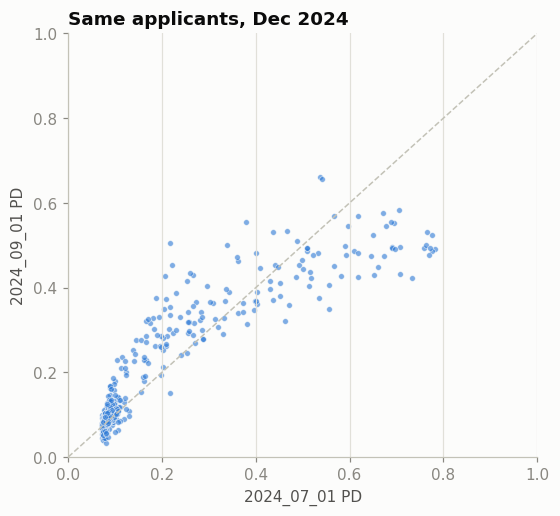

In [19]:
wide = preds.pivot_table(index=["customer_id", "snapshot_date"], columns="model_name",
                         values="model_predictions").reset_index()
pairs = [(a, b) for i, a in enumerate(MODELS) for b in MODELS[i + 1:]]
rows = []
for a, b in pairs:
    both = wide.dropna(subset=[a, b])
    for d, g in both.groupby("snapshot_date"):
        top_a = g[a] >= g[a].quantile(.9)
        top_b = g[b] >= g[b].quantile(.9)
        rows.append({"model_a": short(a), "model_b": short(b), "month": d.date(), "n": len(g),
                     "spearman": g[a].corr(g[b], method="spearman"),
                     "mean_a": g[a].mean(), "mean_b": g[b].mean(),
                     "top_decile_overlap": (top_a & top_b).sum() / top_a.sum()})
comparison = pd.DataFrame(rows)
if len(comparison):
    display(comparison.round(3))
    a, b = next((a, b) for a, b in reversed(pairs) if wide[[a, b]].notna().all(axis=1).any())
    last = wide.dropna(subset=[a, b])
    last = last[last["snapshot_date"].eq(last["snapshot_date"].max())]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(last[a], last[b], s=14, color=SERIES[0], alpha=0.6, edgecolor=SURFACE, linewidth=0.5)
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=f"{short(a)} PD", ylabel=f"{short(b)} PD",
           title=f"Same applicants, {last['snapshot_date'].max():%b %Y}")
    ax.grid(axis="both")
else:
    print("No month was scored by more than one model.")

## 8. Monitoring summary

One row per model and month, combining everything above. The action column uses these rules:

* **investigate**: prediction PSI ≥ 0.25, a feature that is 100% missing, AUC below the floor, or calibration off by more than the tolerance
* **watch**: prediction PSI ≥ 0.10, any feature alert, or AUC down more than 0.03 from the model's first matured month
* **ok**: otherwise

In [20]:
summary = (preds.groupby(["model_name", "snapshot_date"])
           .agg(n=("model_predictions", "size"), mean_pd=("model_predictions", "mean")).reset_index())
summary = summary.merge(pred_psi[["model_name", "snapshot_date", "psi"]].rename(columns={"psi": "prediction_psi"}),
                        on=["model_name", "snapshot_date"], how="left")
fp = feat_psi.groupby(["model_name", "snapshot_date"]).agg(
    feature_alerts=("status", lambda s: int(s.eq("alert").sum())),
    worst_feature=("psi", lambda s: feat_psi.loc[s.idxmax(), "feature_name"]),
    worst_feature_psi=("psi", "max"),
    fully_missing=("current_missing_rate", lambda s: int(s.eq(1).sum()))).reset_index()
summary = summary.merge(fp, on=["model_name", "snapshot_date"], how="left")
summary = summary.merge(metrics[["model_name", "prediction_date", "label_coverage", "auc", "calibration_ratio"]]
                        .rename(columns={"prediction_date": "snapshot_date"}),
                        on=["model_name", "snapshot_date"], how="left")
baseline_auc = summary.dropna(subset=["auc"]).groupby("model_name")["auc"].first()
summary["auc_change"] = summary["auc"] - summary["model_name"].map(baseline_auc)

def action(r):
    reasons_hi, reasons_lo = [], []
    if r.prediction_psi >= PSI_ALERT: reasons_hi.append("score PSI alert")
    elif r.prediction_psi >= PSI_WARNING: reasons_lo.append("score PSI warning")
    if r.fully_missing > 0: reasons_hi.append(f"{int(r.fully_missing)} features 100% missing")
    elif r.feature_alerts > 0: reasons_lo.append(f"{int(r.feature_alerts)} feature alerts")
    if pd.notna(r.auc):
        if r.auc < AUC_FLOOR: reasons_hi.append("AUC below floor")
        elif r.auc_change < -AUC_DROP_WARNING: reasons_lo.append("AUC drop")
        if abs(r.calibration_ratio - 1) > CALIBRATION_TOLERANCE: reasons_hi.append("miscalibrated")
    level = "investigate" if reasons_hi else "watch" if reasons_lo else "ok"
    return pd.Series({"action": level, "reasons": "; ".join(reasons_hi + reasons_lo) or "-",
                      "labels": "matured" if pd.notna(r.auc) else "pending"})

summary = pd.concat([summary, summary.apply(action, axis=1)], axis=1)
summary["model"] = summary["model_name"].map(short)
(summary[["model", "snapshot_date", "n", "mean_pd", "prediction_psi", "feature_alerts", "worst_feature",
          "worst_feature_psi", "labels", "auc", "auc_change", "calibration_ratio", "action", "reasons"]]
 .sort_values(["model", "snapshot_date"]).round(3).reset_index(drop=True))

,model,snapshot_date,n,mean_pd,prediction_psi,feature_alerts,worst_feature,worst_feature_psi,labels,auc,auc_change,calibration_ratio,action,reasons
0,2024_01_01,2024-01-01,485,0.279,0.052,6.0,fe_4_mean_12m,1.885,matured,0.870,0.000,0.940,watch,6 feature alerts
1,2024_01_01,2024-02-01,518,0.300,0.076,6.0,fe_8_mean_12m,2.875,matured,0.837,-0.033,1.056,watch,6 feature alerts; AUC drop
2,2024_01_01,2024-03-01,511,0.305,0.043,6.0,fe_9_mean_12m,2.710,matured,0.828,-0.042,0.929,watch,6 feature alerts; AUC drop
3,2024_01_01,2024-04-01,513,0.293,0.034,6.0,fe_10_mean_12m,2.727,matured,0.830,-0.040,1.057,watch,6 feature alerts; AUC drop
4,2024_01_01,2024-05-01,491,0.302,0.076,6.0,fe_3_mean_12m,2.973,matured,0.841,-0.029,0.994,watch,6 feature alerts
5,2024_01_01,2024-06-01,498,0.290,0.037,6.0,fe_8_mean_12m,2.828,matured,0.879,0.008,0.933,watch,6 feature alerts
6,2024_07_01,2024-07-01,505,0.211,1.208,6.0,fe_4_mean_12m,25.328,pending,NaN,NaN,NaN,investigate,score PSI alert; 6 features 100% missing
7,2024_07_01,2024-08-01,543,0.206,1.138,6.0,fe_4_mean_12m,25.328,pending,NaN,NaN,NaN,investigate,score PSI alert; 6 features 100% missing
8,2024_07_01,2024-09-01,493,0.216,1.251,6.0,fe_4_mean_12m,25.328,pending,NaN,NaN,NaN,investigate,score PSI alert; 6 features 100% missing
9,2024_07_01,2024-10-01,456,0.190,1.212,6.0,fe_4_mean_12m,25.328,pending,NaN,NaN,NaN,investigate,score PSI alert; 6 features 100% missing


## 9. Findings (as of the data in `datamart/gold` when this was written)

**Performance (credit_model_2024_01_01, the only model with matured labels).** AUC stayed between about 0.83 and 0.88
across the six matured cohorts (Jan–Jun 2024 applications, evaluated Jul–Dec 2024). Mean predicted PD tracks the
observed default rate within a few points, so the model is still discriminating and roughly calibrated.

**Clickstream PSI alerts for V1 are mostly a construction artefact, not behaviour change.** The V1 PSI reference
is Jan–Apr 2023 applications, when the 12-month clickstream mean covers only 1–4 months of history
(clickstream starts Jan 2023). Those months have 2–3× the spread of full-window months (section 6), so every
later month looks drifted. Non-clickstream features stay well under 0.1, and so does V1's prediction PSI.

**From July 2024 there is no clickstream data for new applicants.** Every `fe_*` feature is 100% missing from Jul 2024,
which is why V2 shows PSI ≈ 25.3 (the ceiling) for all of them every month. Its prediction PSI is also on alert:
the imputer fills every clickstream value, which shifts scores. This is real data loss in the source
(`feature_clickstream.csv` has no rows for those customers), not a pipeline bug.

**Suggested follow-ups**

1. Build PSI references only from months where the clickstream window is full (Dec 2023 onwards for a 12-month window).
2. Treat clickstream source coverage as its own alert (`has_clickstream` share) instead of drift.
3. Retrain without `fe_*` features, or with an explicit missing-clickstream path, before scoring applicants from July 2024 onward.
4. `credit_model_2024_09_01` has predictions (Sep–Dec 2024) but no PSI outputs yet: run its PSI monitoring.
   On the shared months it ranks applicants very similarly to V2 (Spearman ≈ 0.9, section 7).
5. Re-run this notebook once Jan 2025+ label partitions exist, to evaluate V2/V3 on outcomes.